**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Tutorial 0, notebook 3 of 3

| | |
|---|---|
| **Goal** | Describe your sector: volume and growth, technology mix and geography, at family and application level. |
| **Before this** | 01 · PATSTAT basics, and the CPC codes and keywords of your sector from Step 0 |
| **Time** | 30 min |
| **PATSTAT environment** | PROD |

← [01 · PATSTAT on TIP](01_patstat_basics.ipynb) &nbsp;|&nbsp; — →

# Step 1 of the PW: General description of the sector

| Question to answer (Presentation deck, Step 1) | How we measure it in this notebook |
|---|---|
| How big is the field, and is it growing, flat or declining? | Families per earliest priority year; growth (%) of the sector compared with the growth (%) of all patents, and the sector's share of all PATSTAT families |
| Which technologies make up the field? Which classes dominate, and how is the mix shifting? | Fractional counts by CPC subclass, and by WIPO technology field, over time (area plots and heat maps) |
| Where is it happening? | Filing offices (IP5, each one compared with its own total); applicant and inventor countries (fractional counts, maps and heat maps) |
| Is the field patent-heavy, or does it rely on secrecy? | Signals of patent use in our data (international filing, grants, who files, share of computing classes), read together with the literature |

## 1. Setup and configuration

In [35]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, distinct, func, literal, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # import the needed tables for the extractions
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
    TLS230_APPLN_TECHN_FIELD,
    TLS901_TECHN_FIELD_IPC,
)

### Our sector

The sector is **Humanoid robots**, for the client Electrolux. It is not defined here with CPC codes: it is the final set of families that Step 0 kept with the sector rules (validated in Step 0). This notebook reads it from the files that Step 0 saved.

In [36]:
import json

# ---------------------------------------------------------------- environment
ENV = "PROD"                                       # the tables that Step 0 saved on PROD (on TEST the numbers mean nothing)
DATA_DIR = Path("data") / ENV / "humanoid_robots"  # written by Step 0, section 5.12 "Save the outputs"
OUTPUT_DIR = Path("outputs/step1")                 # name this how you wish

# ---------------------------------------------------------------- sector definition
SECTOR_NAME = "Humanoid robots"                    # the families are the ones kept by the sector rules of Step 0: no CPC prefixes here

# ---------------------------------------------------------------- time window: we read it from Step 0, so the two notebooks always agree
meta = json.loads((DATA_DIR / "dataset_metadata.json").read_text())
YEAR_MIN, YEAR_MAX = meta["window"]                # 1990 up to the current year

FAMILY_TIME_COLUMN = "earliest_filing_year"        # family level: earliest priority year (Step 0 saved it as `priority_year`)
APPLN_TIME_COLUMN = "appln_filing_year"            # application level: we use it only for the filing offices (Section 9.1)

# Last years that are still incomplete in PATSTAT (Step 0 rule: current year - 3)
TRUNCATED_YEARS = {"appln_filing_year": 3, "earliest_filing_year": 3, "earliest_publn_year": 1}

# ---------------------------------------------------------------- counting rules
IPR_TYPE = "PI"                                    # patents of invention only (same as Step 0: utility models "UM" are out)
IP5_OFFICES = ("EP", "US", "CN", "JP", "KR")       # the five largest patent offices (Section 9)
TOP_N = 8                                          # categories shown in tables and figures; the rest is "Other"

# ---------------------------------------------------------------- derived
LAST_COMPLETE_YEAR = meta["last_complete_year"]    # the same year that Step 0 used to flag the truncated families
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Sector: {SECTOR_NAME} | env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} | family year: {FAMILY_TIME_COLUMN} "
      f"| application year: {APPLN_TIME_COLUMN} | complete years up to {LAST_COMPLETE_YEAR}")

Sector: Humanoid robots | env: PROD | years 1990-2026 | family year: earliest_filing_year | application year: appln_filing_year | complete years up to 2023


## 2. Two levels of analysis: applications and families

Before counting anything, we must decide **what we count**. PATSTAT offers two natural units.

**An application (`appln_id`)** is one request for protection filed at one patent office. Each row of `tls201_appln` is an application, identified by `appln_id`. The office is in `appln_auth` (e.g. `EP` = European Patent Office, `US`, `CN`, `IT`, and `WO` for an international application filed through the PCT, see Section 4).

**A family (`docdb_family_id`)** groups all the applications that protect the **same invention** in different offices. A patent is valid only in the country that grants it: to be protected in several countries, an applicant files the same invention in several offices, and each filing becomes a separate application. PATSTAT links them with the same `docdb_family_id`.

**A toy example.** An Italian company invents a new wave energy converter:

| Step | Office (`appln_auth`) | Filing year | `appln_id` | `docdb_family_id` |
|---|---|---|---|---|
| first filing (the **priority**) | IT | 2019 | 101 | 9001 |
| international application through the PCT, within 12 months | WO | 2020 | 102 | 9001 |
| European application | EP | 2021 | 103 | 9001 |
| national applications | US, CN | 2021 | 104, 105 | 9001 |

5 applications, **1 invention**. Counting applications gives 5, counting families gives 1.

| | Application level (`appln_id`) | Family level (`docdb_family_id`) |
|---|---|---|
| What one unit is | a filing at one office | an invention |
| Answers questions like | How much protection is sought, and where? | How many inventions are produced, by whom, in which technologies? |
| Watch out | an invention filed in many offices counts many times | each invention counts once |
| Year used here | the application's filing year | the earliest priority year of the family |

Either the  **family or application id could be the reference units for the PW** (one invention = one count). In this notebook every plot is shown at **both levels**, side by side, so you can see how much the picture changes.

The sector is always selected at family level: a family belongs to the sector if any of its applications has one of the sector CPC codes. At application level we then count all the applications of those families. So the two levels look at the same patents and differ only in *how we count*.

### 2.1 Selecting the sector

We do not query PATSTAT again, apart from one small query in Section 7.1. We read here the tables that Step 0 saved (section 5.12) and the benchmark: all the families in PATSTAT.

In [37]:
def load_table(name):
    """A table saved by Step 0: parquet, or pickle if pyarrow was missing there."""
    for suffix, reader in ((".parquet", pd.read_parquet), (".pkl", pd.read_pickle)):
        if (DATA_DIR / f"{name}{suffix}").exists():
            return reader(DATA_DIR / f"{name}{suffix}")
    raise FileNotFoundError(f"{name} is not in {DATA_DIR}: run Step 0 (section 5.12) on {ENV} first")


families = load_table("families")                      # one row per family of the sector
applications = load_table("applications")              # one row per application of those families
family_cpc = load_table("family_cpc")
family_wipo = load_table("family_wipo")
family_inventors = load_table("family_inventors")
family_applicants = load_table("family_applicants")

# the benchmark: ALL families in PATSTAT (same type of right, same years), by priority year and by IP5 office
baseline = (load_table("baseline_year").assign(year=lambda d: d["priority_year"].astype(int))
            .set_index("year")["families"])
baseline_office = (load_table("baseline_office").rename(columns={"filing_year": "year", "families": "all_families"})
                   .assign(year=lambda d: d["year"].astype(int)))

families = families[families["priority_year"].between(YEAR_MIN, YEAR_MAX)].copy()
mature = families[families["priority_year"] <= LAST_COMPLETE_YEAR]        # the families of the complete years
n_complete = len(mature)
print(f"{SECTOR_NAME}: {len(families):,} families with priority year {int(families['priority_year'].min())}-{int(families['priority_year'].max())}, "
      f"of which {n_complete:,} in complete years (<= {LAST_COMPLETE_YEAR}) and {len(families) - n_complete:,} in the incomplete years")
print(f"Rows read: " + ", ".join(f"{name} {len(t):,}" for name, t in
                                  {"applications": applications, "family_cpc": family_cpc, "family_wipo": family_wipo,
                                   "family_inventors": family_inventors, "family_applicants": family_applicants}.items()))

Humanoid robots: 5,033 families with priority year 1990-2025, of which 3,609 in complete years (<= 2023) and 1,424 in the incomplete years
Rows read: applications 7,359, family_cpc 13,764, family_wipo 7,311, family_inventors 5,576, family_applicants 6,418


In [38]:
# We check that every table of Step 0 has the columns that this notebook reads: if Step 0 is rerun or merged and one name
# changes, We want to stop here with a clear message, not in a cell in the middle of Section 9
REQUIRED = {
    "families": ["docdb_family_id", "priority_year", "has_pct", "n_applns", "n_jurisdictions", "jurisdictions"],
    "applications": ["docdb_family_id", "appln_id", "appln_auth", "appln_kind", "appln_filing_date",
                     "appln_filing_year", "earliest_filing_year", "granted", "docdb_family_size"],
    "family_cpc": ["docdb_family_id", "cpc_symbol", "subclass", "is_tagging"],
    "family_wipo": ["docdb_family_id", "techn_field_nr", "techn_field", "techn_sector", "weight"],
    "family_inventors": ["docdb_family_id", "inventor_country", "weight"],
    "family_applicants": ["docdb_family_id", "applicant", "country", "applicant_type", "weight"],
    "baseline_year": ["priority_year", "families"],
    "baseline_office": ["office", "filing_year", "families"],
}
tables = {"families": families, "applications": applications, "family_cpc": family_cpc, "family_wipo": family_wipo,
          "family_inventors": family_inventors, "family_applicants": family_applicants,
          "baseline_year": load_table("baseline_year"), "baseline_office": load_table("baseline_office")}

# one line for every column that is missing
problems = [f"{t}: column {c} is missing" for t, cols in REQUIRED.items() for c in cols if c not in tables[t].columns]
problems += [f"dataset_metadata.json: key {k} is missing" for k in ("window", "last_complete_year") if k not in meta]
assert not problems, "The tables of Step 0 are not what Step 1 reads:\n" + "\n".join(problems)
print("The tables of Step 0 have all the columns that Step 1 reads")

The tables of Step 0 have all the columns that Step 1 reads


### 2.2 Example: one real family, application by application

Let us look at the sector family with the most applications. Each row is one `appln_id`; they all share the same `docdb_family_id`.

In [39]:
# the sector family with the most applications (Step 0 saved it as `n_applns`)
example_family_id = int(families.sort_values(["n_applns", "docdb_family_id"], ascending=[False, True]).iloc[0]["docdb_family_id"])

example_family = (
    applications.loc[applications["docdb_family_id"] == example_family_id,
                     ["docdb_family_id", "appln_id", "appln_auth", "appln_kind", "appln_filing_date", "appln_filing_year",
                      "earliest_filing_year", "granted", "docdb_family_size"]]
    .assign(earliest_publn_year=np.nan)    # Step 0 did not save the publication year: We leave the column empty so that Section 3 runs as it is
    .sort_values("appln_filing_date")
)
example_family

,docdb_family_id,appln_id,appln_auth,appln_kind,appln_filing_date,appln_filing_year,earliest_filing_year,granted,docdb_family_size,earliest_publn_year
364,19189479,294873747,DE,T,2002-12-26,2002,2001.0,N,42,NaN
467,19189479,415001523,KR,A,2002-12-26,2002,2001.0,Y,42,NaN
468,19189479,15991674,EP,A,2002-12-26,2002,2001.0,Y,42,NaN
472,19189479,25490760,WO,W,2002-12-26,2002,2001.0,N,42,NaN
483,19189479,415001232,KR,A,2002-12-26,2002,2001.0,Y,42,NaN
485,19189479,124369,EP,A,2002-12-26,2002,2001.0,Y,42,NaN
498,19189479,25490759,WO,W,2002-12-26,2002,2001.0,N,42,NaN
449,19189479,414990694,KR,A,2002-12-26,2002,2001.0,Y,42,NaN
501,19189479,38356022,JP,A,2002-12-26,2002,2001.0,Y,42,NaN
507,19189479,38356019,JP,A,2002-12-26,2002,2001.0,Y,42,NaN


How to read it:

- `appln_auth` tells you in which offices the invention was filed: this is **where protection is sought**.
- `appln_kind` is the type of application: `A` for a patent application, `W` for an international application filed through the PCT (codes are 2 characters long, e.g. `'A '`).
- `granted` = `Y` if that application was granted. Each office decides on its own: the same invention can be granted in one office and refused in another.
- `docdb_family_size` is the number of applications in the family: it is the same on every row.

## 3. Which year? Three ways to date a patent

Each application in `tls201_appln` carries three years. The same invention can therefore be placed in different years depending on the column you choose.

| Column | What it is | Use it when… | Incomplete recent years |
|---|---|---|---|
| `appln_filing_year` | year **this application** was filed at its office | you count applications | ~3 years (applications become visible only after publication, ~18 months) |
| `earliest_publn_year` | year of the **first publication** of the application | you want the most up-to-date series (EPO statistics use it) | only the current year |
| `earliest_filing_year` | year of the **earliest priority**: the first filing of the invention anywhere in the world | you want the date closest to the invention | ~3 years |

At **family level** we need one year per family: we take the **smallest `earliest_filing_year`** among its applications, i.e. the first time the invention was filed anywhere (PW rule). At **application level** we use the application's own `appln_filing_year`. Both choices can be changed in the configuration (`FAMILY_TIME_COLUMN`, `APPLN_TIME_COLUMN`).


On our example family:

In [40]:
years = example_family[["appln_id", "appln_auth", "appln_filing_year", "earliest_publn_year", "earliest_filing_year"]]
family_year = example_family["earliest_filing_year"].min()
print(f"Family {example_family_id}: {len(example_family)} applications filed between "
      f"{example_family['appln_filing_year'].min()} and {example_family['appln_filing_year'].max()}; "
      f"family year (earliest priority) = {family_year}")
years

Family 19189479: 42 applications filed between 2002 and 2004; family year (earliest priority) = 2001.0


,appln_id,appln_auth,appln_filing_year,earliest_publn_year,earliest_filing_year
364,294873747,DE,2002,NaN,2001.0
467,415001523,KR,2002,NaN,2001.0
468,15991674,EP,2002,NaN,2001.0
472,25490760,WO,2002,NaN,2001.0
483,415001232,KR,2002,NaN,2001.0
485,124369,EP,2002,NaN,2001.0
498,25490759,WO,2002,NaN,2001.0
449,414990694,KR,2002,NaN,2001.0
501,38356022,JP,2002,NaN,2001.0
507,38356019,JP,2002,NaN,2001.0


At application level this family adds one count to each of the filing years above; at family level it adds a single count, to its priority year. Section 7.1 shows the effect on the whole sector.

## 4. Other methodological choices

These choices are the same for every number in the notebook. State them in the technical appendix of your deck.

**Truncation.** Applications are published 18 months after the priority date and reach PATSTAT with a further delay, so the last ~3 filing or priority years are incomplete (`LAST_COMPLETE_YEAR` in the configuration). They are **shaded in grey in every figure and excluded from growth**: a drop in those years is not a decline of the sector.

**International applications through the PCT.** The Patent Cooperation Treaty (PCT) lets an applicant file **one international application**, handled by WIPO, that can later be extended to more than 150 countries. In PATSTAT it has `appln_auth = 'WO'` and `appln_kind` starting with `W`. Filing through the PCT costs money, so it signals an invention the applicant wants to protect abroad.

| | Family level | Application level |
|---|---|---|
| "via PCT" means… | the family has at least one PCT application | the application is itself a PCT application |

**Fractional counting.** In this code, when a family has applicants from different countries, each country receives a fraction of the family, proportional to its number of distinct applicants. For example, a family with 2 Italian applicants and 1 German applicant counts 2/3 for IT and 1/3 for DE. Each family then sums to exactly 1. The same rule applies to inventors and to technology classes: a family in 4 CPC subclasses gives 1/4 to each. At application level the same rule splits each application.



## 5. Tables and attributes used in Step 1

In Step 1 we read the tables that Step 0 saved in `data/PROD/humanoid_robots/`, and we run one small query in Section 7.1 (the publication year). Every count below is a count of DOCDB families.

| Table (file of Step 0) | Grain (one row per…) | Attributes used | Used for |
|---|---|---|---|
| `families` | family | `docdb_family_id`, `priority_year`, `has_pct`, `n_applns`, `n_jurisdictions`, `jurisdictions` | volume, PCT, offices of the family, signals of patent use |
| `applications` | application | `appln_auth` (office), `appln_filing_year`, `appln_kind`, `granted`, `docdb_family_size` | filing offices (Section 9.1), grants (Section 10.1), the example family |
| `family_cpc` | family × CPC symbol | `cpc_symbol`, `subclass`, `is_tagging` | CPC subclass mix |
| `family_wipo` | family × WIPO field | `techn_field`, `techn_sector`, `weight` (sums to 1 per family) | WIPO technology fields |
| `family_inventors` | family × inventor country | `inventor_country`, `weight` | inventor countries |
| `family_applicants` | family × applicant | `applicant`, `country`, `applicant_type`, `weight` | applicant countries and types |
| `baseline_year` | priority year | `families` = all families in PATSTAT | growth of all patents, share of the sector |
| `baseline_office` | IP5 office × filing year | `families` = all families with an application at the office | weight of the sector inside each office |

Things to know about these attributes:

- The baseline counts all families of PATSTAT with the same type of right as the sector (PI), so the comparison is like with like.
- The subclass is the first 4 characters of `cpc_symbol` (already without blanks). We leave out the tagging symbols (Y02, Y10), as in Step 0.
- An unknown country is `''` for applicants and `'??'` for inventors: these are left out of the country shares, and I print how many families this affects.
- `earliest_publn_year` was not saved by Step 0: Section 7.1 reads it from PATSTAT.

## 6. Some other examples to look at


### 6.1 What we count

The unit is the family, dated by its earliest priority year (decision of Step 0). The sector is the table `families`; the benchmark is `baseline` (all the families in PATSTAT). The application level appears only in Sections 7.1 and 9.1.

### 6.2 Counting functions

Each function returns a small `DataFrame` computed in pandas from the tables of Step 0. Counts are in `n` (whole families) or `n_frac` (fractional families: every family sums to 1).

In [41]:
def fractional_by_cpc_subclass():
    """Fractional counts by CPC subclass (first 4 characters) and priority year.

    Each family is split equally across its distinct subclasses (it sums to 1). The tagging symbols (Y02, Y10) are left out,
    as in Step 0: they are cross-cutting labels, not a technology.
    """
    pairs = (family_cpc.loc[~family_cpc["is_tagging"], ["docdb_family_id", "subclass"]].drop_duplicates()
             .merge(families[["docdb_family_id", "priority_year"]], on="docdb_family_id"))
    pairs["n_frac"] = 1.0 / pairs.groupby("docdb_family_id")["subclass"].transform("size")
    return pairs.rename(columns={"priority_year": "year"}).groupby(["subclass", "year"], as_index=False)["n_frac"].sum()


def fractional_by_techn_field():
    """Fractional counts by WIPO technology field (1-35) and priority year.

    Step 0 already normalised the weights of `family_wipo` so that every family sums to 1 (and merged the names of the fields).
    """
    out = family_wipo.merge(families[["docdb_family_id", "priority_year"]], on="docdb_family_id")
    return out.rename(columns={"priority_year": "year", "weight": "n_frac"})[
        ["docdb_family_id", "techn_field_nr", "techn_field", "techn_sector", "year", "n_frac"]]


def first_filing_offices():
    """The national office(s) where each family was first filed (the PCT office WO is not a country).

    If several offices share the first filing date, the family is split equally among them (it sums to 1).
    """
    a = applications.loc[applications["appln_auth"] != "WO", ["docdb_family_id", "appln_auth", "appln_filing_date"]].copy()
    d = pd.to_datetime(a["appln_filing_date"], errors="coerce")
    a["filing_date"] = d.where(d.dt.year < 9000)                                        # unknown dates (9999-12-31) are left out
    first = a[a["filing_date"] == a.groupby("docdb_family_id")["filing_date"].transform("min")]
    first = first.drop_duplicates(["docdb_family_id", "appln_auth"]).rename(columns={"appln_auth": "country"})
    first["n_frac"] = 1.0 / first.groupby("docdb_family_id")["country"].transform("size")
    return first[["docdb_family_id", "country", "n_frac"]]


def fractional_by_country(role="applicant"):
    """One row per family and country, with its fraction of the family (role: 'applicant' or 'inventor').

    Each family is split among its distinct applicants (or inventors) with a KNOWN country, so it still sums to 1 (`source` = "known").
    PATSTAT leaves the country empty for most families filed only in China (and for many in Japan): for the families with NO known
    country I use the national office(s) of the first filing instead (`source` = "first office"). Section 9.2 shows both.
    """
    years = families[["docdb_family_id", "priority_year"]]
    if role == "applicant":
        t = family_applicants.loc[family_applicants["country"].str.strip() != "", ["docdb_family_id", "applicant", "country"]].drop_duplicates()
        t["n_frac"] = 1.0 / t.groupby("docdb_family_id")["applicant"].transform("nunique")     # one applicant = one share of the family
    else:
        t = family_inventors.loc[family_inventors["inventor_country"] != "??", ["docdb_family_id", "inventor_country", "weight"]].rename(
            columns={"inventor_country": "country"})
        t["n_frac"] = t["weight"] / t.groupby("docdb_family_id")["weight"].transform("sum")    # share of the inventors that have a known country
    known = t[["docdb_family_id", "country", "n_frac"]].assign(source="known")
    first = first_filing_offices()
    first = first[~first["docdb_family_id"].isin(known["docdb_family_id"])].assign(source="first office")     # only the families with no known country
    out = pd.concat([known, first], ignore_index=True).merge(years, on="docdb_family_id")
    out = out.rename(columns={"country": "ctry", "priority_year": "year"})
    return out.groupby(["docdb_family_id", "ctry", "year", "source"], as_index=False)["n_frac"].sum()


def count_by_office():
    """Sector families per office and per FILING year of the application: families with at least one application at the office.

    This is the same definition as `baseline_office` (Step 0), so the two can be divided (Section 9.1).
    """
    a = applications.assign(year=pd.to_numeric(applications["appln_filing_year"], errors="coerce"))   # unknown years are not in the window
    a = a[a["year"].between(YEAR_MIN, YEAR_MAX)]
    return (a.groupby(["appln_auth", "year"])["docdb_family_id"].nunique().rename("n").reset_index()
            .rename(columns={"appln_auth": "office"}).astype({"year": int}))

### 6.3 Analysis helpers (pandas)

In [42]:
def shade_truncated(ax):
    """Shade the incomplete (truncated) years on a time axis."""
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15, lw=0,
               label="incomplete years")


def complete_years(df):
    return df[df["year"] <= LAST_COMPLETE_YEAR]


def pool_other(df, category, n=TOP_N, value="n_frac", other_label="Other"):
    """Keep the n largest categories (over the complete years) and pool the rest into 'Other'."""
    top = complete_years(df).groupby(category)[value].sum().nlargest(n).index
    out = df.copy()
    out[category] = out[category].where(out[category].isin(top), other_label)
    return out.groupby([category, "year"], as_index=False)[value].sum()


def share_table(counts):
    """Counts -> percentages that sum to 100 in every column, with 'Other' last and a 'Total' row."""
    shares = counts / counts.sum() * 100
    order = [c for c in shares.sort_values(shares.columns[0], ascending=False).index if c != "Other"]
    order += ["Other"] if "Other" in shares.index else []
    shares = shares.loc[order]
    shares.loc["Total"] = shares.sum()
    return shares


def share_over_time(df, category, value="n_frac"):
    """Year x category table of percentages (each year sums to 100)."""
    wide = df.pivot_table(index="year", columns=category, values=value, aggfunc="sum", fill_value=0)
    wide = wide.div(wide.sum(axis=1), axis=0) * 100
    order = [c for c in complete_years(wide.reset_index()).set_index("year").sum().sort_values(ascending=False).index
             if c != "Other"]
    return wide[order + (["Other"] if "Other" in wide.columns else [])]


def stack_100(ax, shares, title):
    """Stacked area of percentages, y axis from 0% to 100%."""
    palette = [c for i, c in enumerate(plt.get_cmap("tab10").colors) if i != 7]   # no grey: grey = "Other"
    colors = ["lightgrey" if c == "Other" else palette[i % len(palette)] for i, c in enumerate(shares.columns)]
    ax.stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.85)
    shade_truncated(ax)
    ax.set(title=title, xlabel="year", xlim=(YEAR_MIN, YEAR_MAX), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))


def pct_format(df):
    """Percentages with one decimal, as text: a plain table that also prints in a PDF export."""
    return df.apply(lambda col: col.map("{:.1f}%".format) if pd.api.types.is_numeric_dtype(col) else col)


def side_by_side(title, **kw):
    """Two axes next to each other."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), **kw)
    fig.suptitle(title)
    return fig, axes

In [43]:
from matplotlib.colors import PowerNorm

HEAT_FROM = 2000     # We start the heat maps in 2000: before it the sector is too small for a cell to mean anything


def heatmap(table, title, label, name, fmt="{:.0f}", norm=None, figsize=(12, 4.5)):
    """Heat map of a table (rows x columns): the colour and the number in the cell are the same value.
    One hue, light = little, dark = a lot (the same Blues as the world map). Saved in outputs/step1/ for the deck."""
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(table.values, cmap="Blues", norm=norm, aspect="auto")      # one hue, like the map: we never use a rainbow for a count
    ax.set_xticks(range(table.shape[1]))
    ax.set_xticklabels(table.columns)
    ax.set_yticks(range(table.shape[0]))
    ax.set_yticklabels(table.index)
    plt.setp(ax.get_xticklabels(), rotation=90 if table.shape[1] > 12 else 0)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            if v > 0:                                     # we leave the empty cells without a number
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7,
                        color="white" if im.norm(v) > 0.5 else "black")    # white on the dark cells, black on the light ones
    ax.set_title(title)
    ax.set_xlabel(table.columns.name or "")
    fig.colorbar(im, ax=ax, label=label, shrink=0.8)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=200, bbox_inches="tight")      # for the deck
    plt.show()

## 7. Volume: how big is the sector, and is it growing?

We count the sector's families per earliest priority year, and how many of them go through the PCT (international applications). On the right we show the sector's share of all the families in PATSTAT (per 10,000): a sector that grows only as fast as patenting overall would be flat on that plot. The grey band marks the years that are still incomplete: we never read it as a decline.

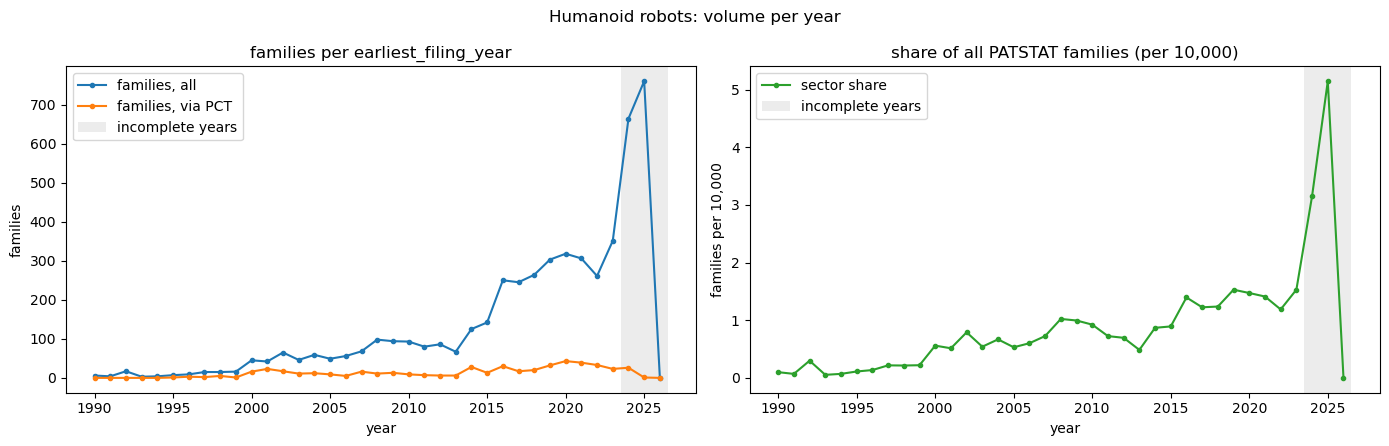

In [44]:
per_year = (families.assign(via_PCT=families["has_pct"].astype(int))
            .groupby("priority_year").agg(all_families=("docdb_family_id", "size"), via_PCT=("via_PCT", "sum"))
            .reindex(range(YEAR_MIN, YEAR_MAX + 1), fill_value=0))
per_year["all_patstat"] = baseline.reindex(per_year.index)                       # all families in PATSTAT, same year
per_year["per_10k"] = 1e4 * per_year["all_families"] / per_year["all_patstat"]   # sector families per 10,000 PATSTAT families

fig, axes = side_by_side(f"{SECTOR_NAME}: volume per year", sharex=True)
axes[0].plot(per_year.index, per_year["all_families"], marker="o", ms=3, label="families, all")
axes[0].plot(per_year.index, per_year["via_PCT"], marker="o", ms=3, label="families, via PCT")
axes[0].set(title=f"families per {FAMILY_TIME_COLUMN}", xlabel="year", ylabel="families")
axes[1].plot(per_year.index, per_year["per_10k"], marker="o", ms=3, color="tab:green", label="sector share")
axes[1].set(title="share of all PATSTAT families (per 10,000)", xlabel="year", ylabel="families per 10,000")
for ax in axes:
    shade_truncated(ax)
    ax.legend()
plt.tight_layout()
plt.show()

### 7.1 The same sector, three ways to date it

The choice of year shifts the curve. Here the sector's applications are dated with each of the three columns, together with the families dated by their earliest priority year. Step 0 did not save the publication year, so I read it here from PATSTAT for the applications of our families: it is the only query of this notebook.

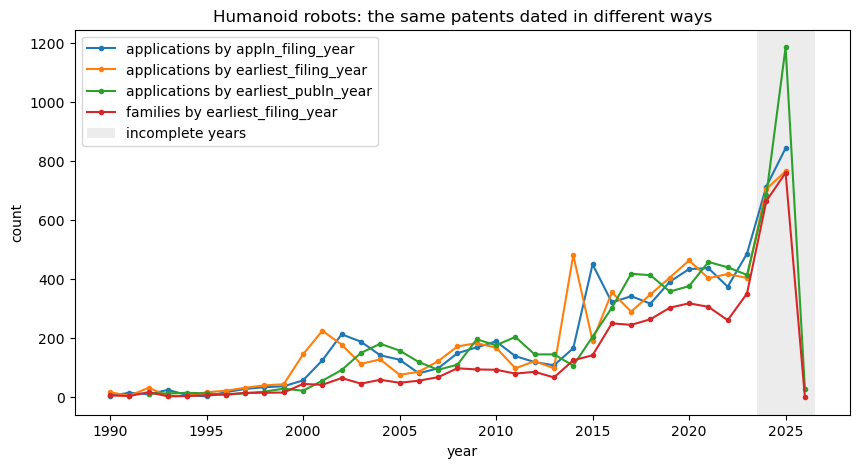

In [45]:
patstat = PatstatClient(env=ENV)     # the only query of this notebook: the publication year of our applications (Step 0 did not save it)
db = patstat.orm()

app_ids = sorted(int(i) for i in applications["appln_id"].unique())
publn = pd.concat(                   # in chunks of 5,000 ids, as in Step 0
    [patstat.df(db.query(TLS201_APPLN.appln_id, TLS201_APPLN.earliest_publn_year)
                .filter(TLS201_APPLN.appln_id.in_(app_ids[k:k + 5000])))
     for k in range(0, len(app_ids), 5000)],
    ignore_index=True,
)
app_years = applications[["appln_id", "appln_filing_year", "earliest_filing_year"]].merge(publn, on="appln_id", how="left")

dating = pd.concat(
    [pd.to_numeric(app_years[col], errors="coerce").loc[lambda s: s.between(YEAR_MIN, YEAR_MAX)]    # unknown years (9999, 0) are out of the window
     .value_counts().sort_index().rename_axis("year").reset_index(name="n").assign(series=f"applications by {col}")
     for col in ("appln_filing_year", "earliest_publn_year", "earliest_filing_year")]
    + [per_year["all_families"].rename_axis("year").reset_index(name="n").assign(series=f"families by {FAMILY_TIME_COLUMN}")],
    ignore_index=True,
)

fig, ax = plt.subplots(figsize=(10, 5))
for series, grp in dating.groupby("series"):
    ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=series)
shade_truncated(ax)
ax.set(title=f"{SECTOR_NAME}: the same patents dated in different ways", xlabel="year", ylabel="count")
ax.legend()
plt.show()



What to notice: dating by **publication** shifts the curve to the right (≈18 months later) and makes recent years look complete; dating by **priority** places inventions at their origin; the **family** curve is lower because each invention counts once.

#### Applications per family

The gap between the application curve and the family curve above is the average number of applications per invention. Here we plot it by priority year. A family filed at one office only counts 1; the higher the number, the more the applicants extended protection abroad. The last years are low for a simple reason: a family needs time to be extended (the national phase of the PCT starts 30 months after the first filing), so we do not read a fall in the grey years, or a small one in the last complete years, as less filing abroad.

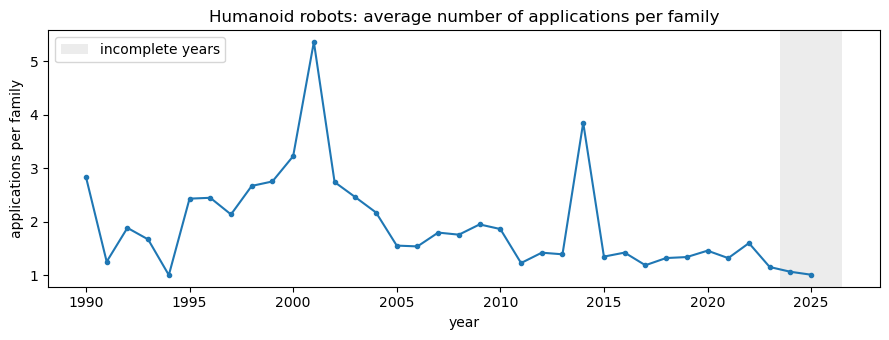

In [46]:
apps_per_family = (families.groupby("priority_year")["n_applns"].mean()
                   .reindex(range(YEAR_MIN, YEAR_MAX + 1)))             # mean of n_applns (Step 0) over the families of each priority year

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(apps_per_family.index, apps_per_family.values, marker="o", ms=3)
shade_truncated(ax)
ax.set(title=f"{SECTOR_NAME}: average number of applications per family", xlabel="year", ylabel="applications per family")
ax.legend()
plt.tight_layout()
plt.show()


### 7.2 Growth: is the sector growing faster than patenting as a whole?

Patenting in general grows over time, so a sector that grows is not necessarily special. For the same years we compare:

- **sector growth (%)** = (sector families in the last complete year − sector families in the first year) / sector families in the first year × 100;
- **growth of all patents (%)**: the same formula on all the families in PATSTAT (`baseline_year` of Step 0, same type of right PI);
- the **CAGR** (compound annual growth rate), which makes periods of different length comparable.

If the sector grows by +150% while all patents grow by +60%, the sector is **gaining weight** in technology. If it grows by +20% while all patents grow by +60%, it is growing, but **less than patenting overall**. Incomplete years are excluded. A small sector moves a lot from one year to the next, so we read four periods (the whole window, since 2000, the last 10 and the last 5 complete years) and also the curve, not only two end points.

In [47]:
end = LAST_COMPLETE_YEAR
starts = (YEAR_MIN, 2000, end - 10, end - 5)       # We look at four periods: the whole window, since 2000, the last 10 and the last 5 complete years

rows = {}
for s in starts:
    n_sec, n_all = per_year["all_families"], per_year["all_patstat"]
    rows[f"{s}-{end}"] = {
        "sector families, first year": int(n_sec[s]),
        "sector families, last year": int(n_sec[end]),
        "sector growth (%)": (n_sec[end] / n_sec[s] - 1) * 100,
        "all patents growth (%)": (n_all[end] / n_all[s] - 1) * 100,
        "sector CAGR (%)": ((n_sec[end] / n_sec[s]) ** (1 / (end - s)) - 1) * 100,       # compound annual growth rate
        "all patents CAGR (%)": ((n_all[end] / n_all[s]) ** (1 / (end - s)) - 1) * 100,
    }
growth = pd.DataFrame(rows).T.rename_axis("period").astype({"sector families, first year": int, "sector families, last year": int})
growth.round({"sector growth (%)": 0, "all patents growth (%)": 0, "sector CAGR (%)": 1, "all patents CAGR (%)": 1})

,"sector families, first year","sector families, last year",sector growth (%),all patents growth (%),sector CAGR (%),all patents CAGR (%)
period,,,,,,
1990-2023,6,351,5750.0,279.0,13.1,4.1
2000-2023,45,351,680.0,185.0,9.3,4.7
2013-2023,67,351,424.0,66.0,18.0,5.2
2018-2023,264,351,33.0,8.0,5.9,1.5


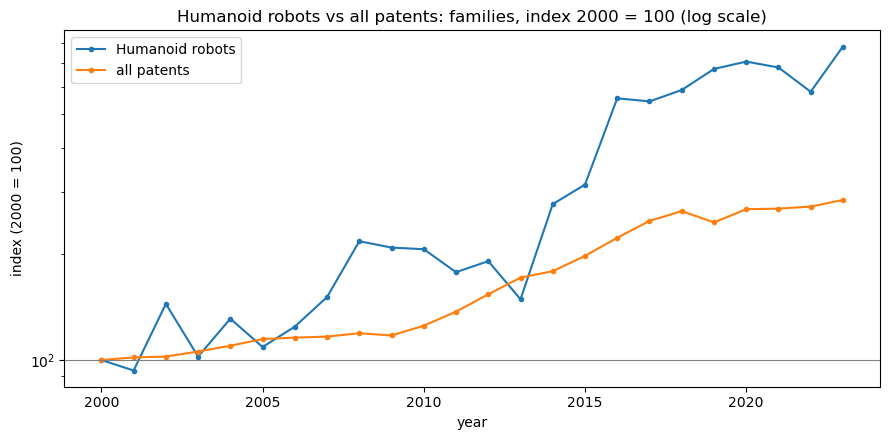

In [48]:
# Index of each year with respect to the first year (= 100): sector vs all patents. Log scale, because the sector grows much faster
start = starts[1]                       # 2000: the first years of the window are too small to be a base
index = per_year.loc[start:end, ["all_families", "all_patstat"]] / per_year.loc[start, ["all_families", "all_patstat"]] * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(index.index, index["all_families"], marker="o", ms=3, label=SECTOR_NAME)
ax.plot(index.index, index["all_patstat"], marker="o", ms=3, label="all patents")
ax.axhline(100, color="grey", lw=0.8)
ax.set(title=f"{SECTOR_NAME} vs all patents: families, index {start} = 100 (log scale)", xlabel="year",
       ylabel=f"index ({start} = 100)", yscale="log")
ax.legend()
plt.tight_layout()
plt.show()

**The last years.** The table stops at the last complete year (Step 0 rule), but the grey years may point up. The table below shows them with the PATSTAT total of the same year: the closer that total is to the one of the last complete year, the more we trust the year; if it is much lower, we read the sector count as a direction, not as a level.

In [49]:
per_year.loc[LAST_COMPLETE_YEAR - 5:, ["all_families", "all_patstat", "per_10k"]].round(2)     # the grey years included: we read them as provisional

,all_families,all_patstat,per_10k
priority_year,,,
2018,264,2132818,1.24
2019,303,1980533,1.53
2020,318,2159703,1.47
2021,306,2167643,1.41
2022,261,2197209,1.19
2023,351,2294523,1.53
2024,664,2104645,3.15
2025,760,1476326,5.15
2026,0,9754,0.00


## 8. Technology mix

### 8.1 CPC subclasses

Which subclasses dominate the sector, and how is the mix shifting? Each family is split equally across its CPC subclasses, so the shares sum to 100%. Many subclasses are *co-classifications*: a humanoid robot family is often also classified in, for example, control systems or computing. They show which neighbouring technologies the sector draws on. The tagging symbols (Y02, Y10) are left out. In this sector B62D is mostly B62D 57/032, vehicles with legs: it is the walking robot, not the car (the cell after the table counts them).

In [50]:
# Titles of the subclasses as they appear in the CPC scheme (cooperativepatentclassification.org):
pd.set_option("display.max_colwidth", None)       # showing the full CPC titles
CPC_TITLES = {
    "A61H": "Physical therapy apparatus, e.g. devices for locating or stimulating reflex points in the body; artificial respiration; massage; bathing devices for special therapeutic or hygienic purposes or specific parts of the body",
    "A63H": "Toys, e.g. tops, dolls, hoops or building blocks",
    "B25J": "Manipulators; chambers provided with manipulation devices",
    "B62D": "Motor vehicles; trailers",
    "B65G": "Transport or storage devices, e.g. conveyors for loading or tipping, shop conveyor systems or pneumatic tube conveyors",
    "F16H": "Gearing",
    "G01B": "Measuring length, thickness or similar linear dimensions; measuring angles; measuring areas; measuring irregularities of surfaces or contours",
    "G01C": "Measuring distances, levels or bearings; surveying; navigation; gyroscopic instruments; photogrammetry or videogrammetry",
    "G01L": "Measuring force, stress, torque, work, mechanical power, mechanical efficiency, or fluid pressure",
    "G05B": "Control or regulating systems in general; functional elements of such systems; monitoring or testing arrangements for such systems or elements",
    "G05D": "Systems for controlling or regulating non-electric variables",
    "G06F": "Electric digital data processing",
    "G06N": "Computing arrangements based on specific computational models",
    "G06T": "Image data processing or generation, in general",
    "G06V": "Image or video recognition or understanding",
    "G10L": "Speech analysis or synthesis; speech recognition; speech or voice processing; speech or audio coding or decoding",
    "H02K": "Dynamo-electric machines",
    "H04N": "Pictorial communication, e.g. television",
}

cpc_mix = fractional_by_cpc_subclass()
cpc_pooled = pool_other(cpc_mix, "subclass")

cpc_counts = complete_years(cpc_pooled).groupby("subclass")["n_frac"].sum().to_frame("share of families")
cpc_shares = pct_format(share_table(cpc_counts))
cpc_shares["definition (CPC scheme)"] = [CPC_TITLES.get(s, "") for s in cpc_shares.index]

with_cpc = family_cpc.loc[~family_cpc["is_tagging"], "docdb_family_id"].unique()
n_no_cpc = int((~families["docdb_family_id"].isin(with_cpc)).sum())
print(f"Families with no CPC symbol other than the tagging ones (Y02, Y10): {n_no_cpc:,} of {len(families):,}; they are not in the table below.")
missing = [s for s in cpc_shares.index if s not in CPC_TITLES and s not in ("Other", "Total")]
if missing:
    print(f"No title yet for: {', '.join(missing)}: copy it from the CPC scheme.")
cpc_shares

Families with no CPC symbol other than the tagging ones (Y02, Y10): 948 of 5,033; they are not in the table below.


,share of families,definition (CPC scheme)
subclass,,
B25J,40.4%,Manipulators; chambers provided with manipulation devices
B62D,32.1%,Motor vehicles; trailers
A63H,4.6%,"Toys, e.g. tops, dolls, hoops or building blocks"
G05D,4.3%,Systems for controlling or regulating non-electric variables
G05B,4.1%,Control or regulating systems in general; functional elements of such systems; monitoring or testing arrangements for such systems or elements
G06F,1.6%,Electric digital data processing
G06N,1.2%,Computing arrangements based on specific computational models
G06T,0.7%,"Image data processing or generation, in general"
Other,11.1%,


In [51]:
b62d = family_cpc.loc[family_cpc["subclass"] == "B62D", ["docdb_family_id", "cpc_symbol"]]       # We check what B62D means in this sector
legged = b62d.loc[b62d["cpc_symbol"].str.startswith("B62D57/032"), "docdb_family_id"].nunique()   # B62D 57/032: vehicles with legs
print(f"{legged:,} of {b62d['docdb_family_id'].nunique():,} families with a B62D symbol have B62D57/032")

1,517 of 1,622 families with a B62D symbol have B62D57/032


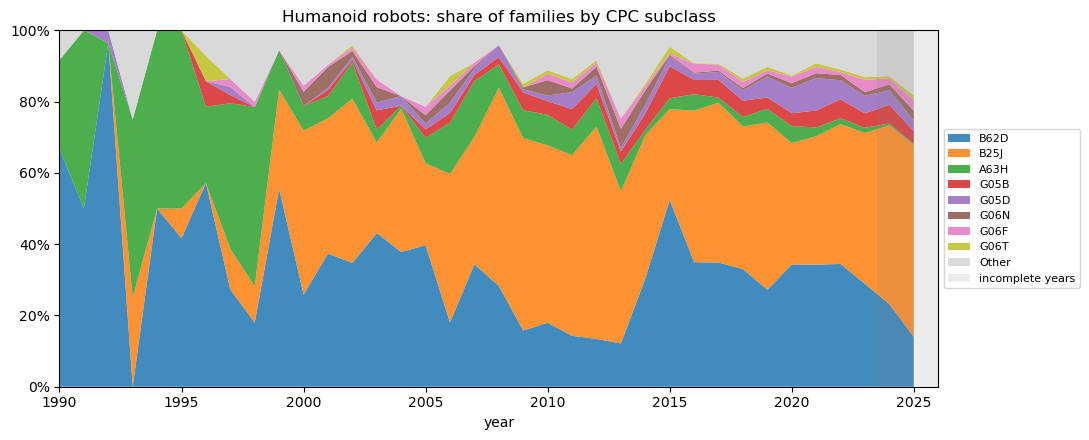

In [52]:
fig, ax = plt.subplots(figsize=(11, 4.5))
stack_100(ax, share_over_time(cpc_pooled, "subclass"), f"{SECTOR_NAME}: share of families by CPC subclass")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

#### Heat map: the subclasses year by year

The same mix as above, read in numbers instead of shares. Each cell is the number of families of one CPC subclass in one priority year; the counts are fractional (every family sums to 1), so the cells of one column add up to the families of that year that have a CPC symbol. The area plot shows the proportions, the heat map shows the volume: a subclass can keep its share and still grow. We use only complete years, from 2000, because before that the sector is too small to read.

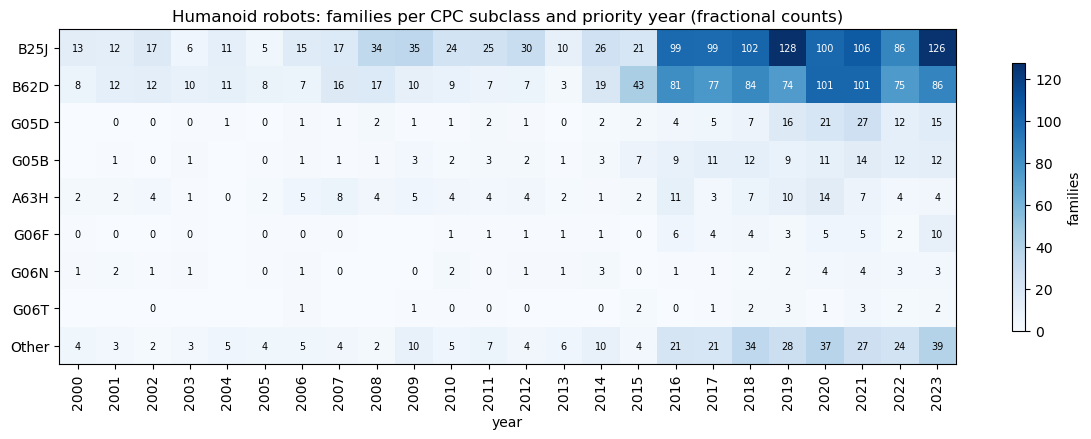

In [53]:
# cpc_pooled is the table of the area plot above: the TOP_N subclasses and Other, fractional counts by year
cpc_table = (cpc_pooled.pivot_table(index="subclass", columns="year", values="n_frac", aggfunc="sum", fill_value=0)
             .loc[:, HEAT_FROM:LAST_COMPLETE_YEAR])                     # We use complete years only
order = [s for s in cpc_table.sum(axis=1).sort_values(ascending=False).index if s != "Other"]
cpc_table = cpc_table.loc[order + (["Other"] if "Other" in cpc_table.index else [])]      # largest subclass on top, Other at the bottom

heatmap(cpc_table, f"{SECTOR_NAME}: families per CPC subclass and priority year (fractional counts)",
        "families", "cpc_heatmap")

### 8.2 WIPO technology fields

WIPO groups all patents into **35 technology fields**, which belong to **5 technology sectors**: Electrical engineering, Instruments, Chemistry, Mechanical engineering, Other fields (tables `tls230` + `tls901`). It is a coarser view than CPC, the same for every country and every sector. Step 0 saved `family_wipo` with the weights already normalised (every family sums to 1) and with the names of the fields.

The question is simple: **of 100 sector families, how many are in each technology sector?** For example, *"X% of humanoid robot families are in Mechanical engineering and Y% in Electrical engineering"*. The shares sum to 100%.

In [54]:
fields = fractional_by_techn_field()

techn_sector_counts = complete_years(fields).groupby("techn_sector")["n_frac"].sum().to_frame("share of families")
techn_sector_shares = share_table(techn_sector_counts)
n_no_wipo = int((~families["docdb_family_id"].isin(family_wipo["docdb_family_id"])).sum())
print(f"Families without a WIPO field: {n_no_wipo:,} of {len(families):,}; they are not in the shares.")
pct_format(techn_sector_shares)

Families without a WIPO field: 6 of 5,033; they are not in the shares.


,share of families
techn_sector,
Mechanical engineering,72.7%
Instruments,12.4%
Other fields,7.6%
Electrical engineering,6.9%
Chemistry,0.3%
Total,100.0%


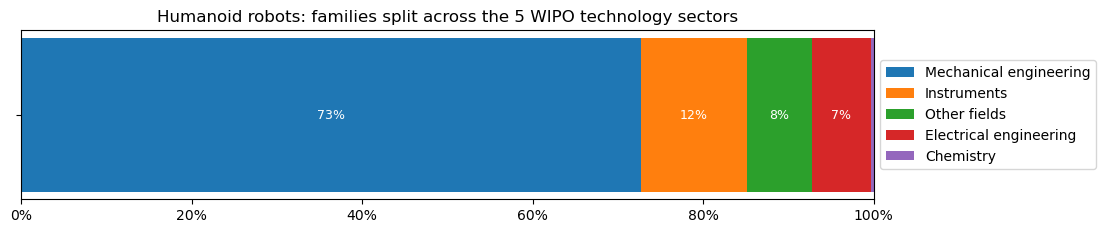

In [55]:
# One bar (= 100%) split into the 5 WIPO technology sectors
bars = techn_sector_shares.drop("Total")["share of families"]

fig, ax = plt.subplots(figsize=(11, 2.2))
left = 0
for techn_sector, v in bars.items():
    ax.barh([""], [v], left=left, label=techn_sector)
    if v >= 5:
        ax.text(left + v / 2, 0, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += v
ax.set(title=f"{SECTOR_NAME}: families split across the 5 WIPO technology sectors", xlim=(0, 100))
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

The same split at the finer level of the 35 fields (largest fields, the rest in **Other**):

In [56]:
field_counts = complete_years(fields).groupby("techn_field")["n_frac"].sum().to_frame("share of families")
top_fields = field_counts["share of families"].nlargest(TOP_N).index
field_counts = field_counts.groupby(field_counts.index.where(field_counts.index.isin(top_fields), "Other")).sum()
pct_format(share_table(field_counts))

,share of families
techn_field,
Handling,46.5%
Transport,24.5%
Control,9.7%
"Furniture, games",7.3%
Computer technology,5.0%
Measurement,1.4%
Medical technology,1.3%
Mechanical elements,1.0%
Other,3.2%


## 9. Geography

### 9.1 Filing offices: the IP5

The **IP5** are the five largest patent offices in the world, which together receive most of the world's patent applications:

| Code (`appln_auth`) | Office |
|---|---|
| `EP` | European Patent Office (EPO) |
| `US` | United States Patent and Trademark Office (USPTO) |
| `CN` | China National Intellectual Property Administration (CNIPA) |
| `JP` | Japan Patent Office (JPO) |
| `KR` | Korean Intellectual Property Office (KIPO) |

Where do applicants seek protection? Offices with many sector filings are the markets that applicants consider worth protecting. One family is usually filed at several offices, so the office counts overlap and do not sum to the number of families: I show how many sector families have an application at each office.

We do not compare offices with raw counts. Each office has its own size and its own practice (costs, examination, utility models). For every office and every filing year I divide the sector's families by all the families that have an application at that office in the same year (`baseline_office`, saved by Step 0). The result, per 10,000 families, is the weight of the sector inside that office: it can be compared across offices and years.

In [57]:
offices = count_by_office()                                       # families with >= 1 application at the office, by filing year
ip5 = offices[offices["office"].isin(IP5_OFFICES)].merge(baseline_office, on=["office", "year"], how="left")
ip5["per_10k"] = 1e4 * ip5["n"] / ip5["all_families"]             # the sector's weight in THAT office in THAT year

complete = complete_years(ip5)
recent = complete[complete["year"] > LAST_COMPLETE_YEAR - 5]     # last 5 complete years
office_table = pd.DataFrame({
    f"sector families, {YEAR_MIN}-{LAST_COMPLETE_YEAR}": complete.groupby("office")["n"].sum(),
    f"per 10,000 of the office's families, {YEAR_MIN}-{LAST_COMPLETE_YEAR}": 1e4 * complete.groupby("office")["n"].sum() / complete.groupby("office")["all_families"].sum(),
    "per 10,000 of the office's families, last 5 complete years": 1e4 * recent.groupby("office")["n"].sum() / recent.groupby("office")["all_families"].sum(),
}).loc[list(IP5_OFFICES)]

at_ip5 = mature["jurisdictions"].fillna("").map(lambda j: bool(set(j.split(";")) & set(IP5_OFFICES)))
print(f"Share of the sector's families with an application at (at least) one IP5 office: {100 * at_ip5.mean():.1f}%")
office_table.round(1)

Share of the sector's families with an application at (at least) one IP5 office: 95.7%


,"sector families, 1990-2023","per 10,000 of the office's families, 1990-2023","per 10,000 of the office's families, last 5 complete years"
office,,,
EP,247,0.7,0.8
US,715,0.7,0.9
CN,2463,1.4,1.7
JP,722,0.6,1.2
KR,399,1.0,0.7


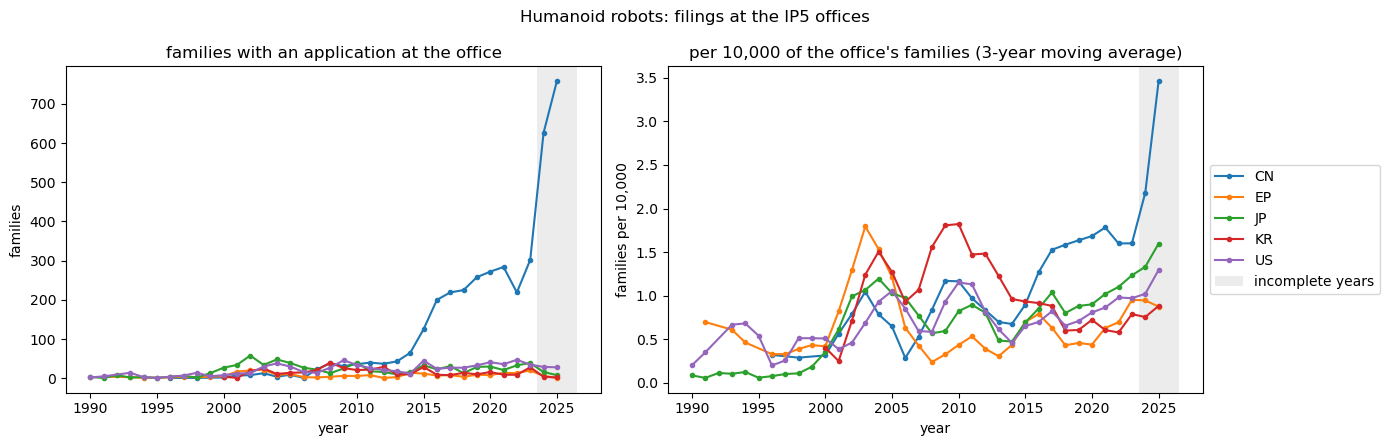

In [58]:
fig, axes = side_by_side(f"{SECTOR_NAME}: filings at the IP5 offices", sharex=True)
for office, g in ip5.groupby("office"):
    axes[0].plot(g["year"], g["n"], marker="o", ms=3, label=office)
    axes[1].plot(g["year"], g["per_10k"].rolling(3, min_periods=1).mean(), marker="o", ms=3, label=office)   # 3-year moving average
axes[0].set(title="families with an application at the office", xlabel="year", ylabel="families")
axes[1].set(title="per 10,000 of the office's families (3-year moving average)", xlabel="year", ylabel="families per 10,000")
for ax in axes:
    shade_truncated(ax)
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

#### Heat map: the IP5 offices year by year

Two heat maps with the same rows and columns. The first shows the raw counts: how many sector families have an application at each office, by filing year. It shows the size of the offices, and the Chinese office dominates. The second divides by all the families of the same office in the same year (`baseline_office`): it is the weight of the sector inside each office, and it is the one I read, because it can be compared across offices and years. The first one is there to show why raw counts cannot be compared. The colour scale of the first is a square root, so that the small offices stay visible. Only complete years, from 2000.

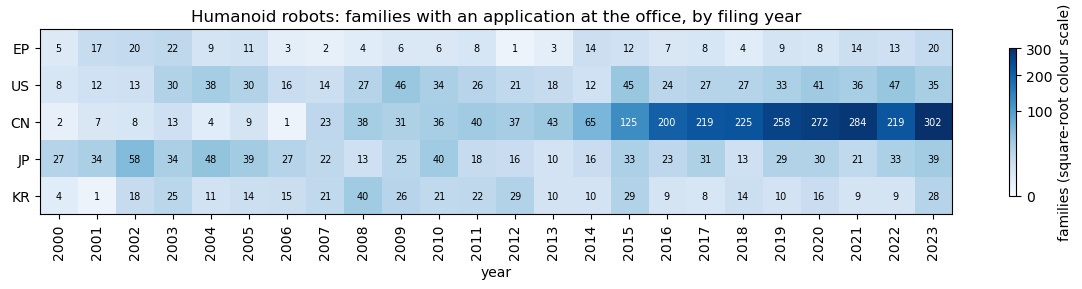

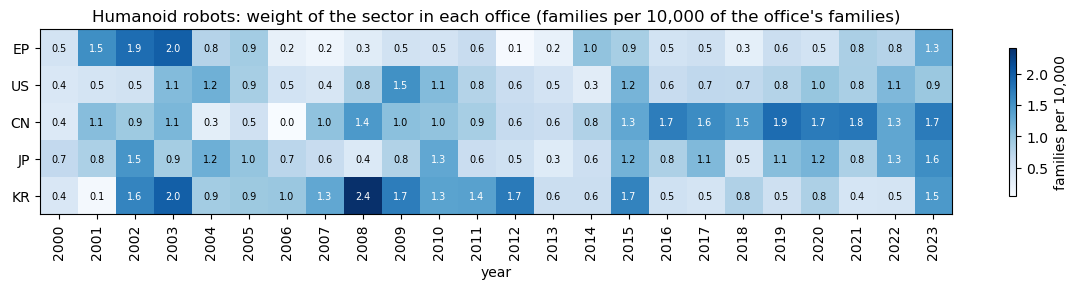

In [59]:
ip5_years = ip5[ip5["year"].between(HEAT_FROM, LAST_COMPLETE_YEAR)]       # ip5 is the table of the section above: n, all_families and per_10k by office and filing year

office_n = (ip5_years.pivot_table(index="office", columns="year", values="n", aggfunc="sum", fill_value=0)
            .reindex(list(IP5_OFFICES), fill_value=0))
# first heat map: the raw counts. The square root keeps the small offices visible next to China
heatmap(office_n, f"{SECTOR_NAME}: families with an application at the office, by filing year",
        "families (square-root colour scale)", "office_heatmap_counts", norm=PowerNorm(0.5, vmin=0), figsize=(12, 3))

# second heat map: the weight of the sector inside each office, the one I read
office_w = (ip5_years.pivot_table(index="office", columns="year", values="per_10k", aggfunc="sum", fill_value=0)
            .reindex(list(IP5_OFFICES), fill_value=0))
heatmap(office_w, f"{SECTOR_NAME}: weight of the sector in each office (families per 10,000 of the office's families)",
        "families per 10,000", "office_heatmap_weight", fmt="{:.1f}", figsize=(12, 3))

#### The same offices, counting applications

Until now we counted families: a family filed at three offices appears three times in the office tables, so the shares cannot be added. If we count applications, each one belongs to exactly one office and the shares add up to 100%. I add the PCT (WO: the international application, which is not yet in any country) and all the other offices (Other). The two units answer two questions: the family count says how many inventions are protected at an office, the application count says where the filing effort goes. Complete years only; each application is dated by its own filing year.

In [60]:
a = applications.assign(year=pd.to_numeric(applications["appln_filing_year"], errors="coerce"))
a = a[a["year"].between(YEAR_MIN, LAST_COMPLETE_YEAR)]                  # complete years, each application dated by its own filing year
a["office"] = a["appln_auth"].where(a["appln_auth"].isin(list(IP5_OFFICES) + ["WO"]), "Other")   # IP5 and the PCT (WO) as they are, every other office in Other

# the two units side by side: applications add up to 100%, families do not (one family is at several offices)
n_appl = a.groupby("office")["appln_id"].nunique()
n_fam = a.groupby("office")["docdb_family_id"].nunique()
by_unit = pd.DataFrame({
    "applications": n_appl,
    "% of the applications": 100 * n_appl / a["appln_id"].nunique(),
    "families with an application there": n_fam,
    "% of the families (they do not add up to 100)": 100 * n_fam / a["docdb_family_id"].nunique(),
}).loc[[o for o in list(IP5_OFFICES) + ["WO", "Other"] if o in n_appl.index]]
by_unit.loc["Total"] = [by_unit["applications"].sum(), by_unit["% of the applications"].sum(), float("nan"), float("nan")]
by_unit.round(1)

,applications,% of the applications,families with an application there,% of the families (they do not add up to 100)
office,,,,
EP,277.0,4.8,246.0,6.9
US,741.0,12.8,644.0,18.0
CN,2530.0,43.6,2459.0,68.6
JP,742.0,12.8,685.0,19.1
KR,414.0,7.1,395.0,11.0
WO,451.0,7.8,439.0,12.2
Other,648.0,11.2,337.0,9.4
Total,5803.0,100.0,NaN,NaN


### 9.2 Applicant and inventor countries (fractional counts)

- **Applicant country**: where the *owners* of the technology are (which firms and countries control it).
- **Inventor country**: where the *research* is carried out.

A gap between the two (e.g. inventors in one country, applicants in another) may point to foreign R&D centres or acquisitions. Each column sums to 100%. A family is split among its applicants (or inventors) that have a known country. PATSTAT leaves the country empty for most families filed only in China (and for many in Japan), so for the families with no known country we use the office of first filing instead: it is a proxy, and we assume that a family filed first at the Chinese office has a Chinese applicant. The table shows both versions: with the completed countries and with the known countries only. For the completed families applicant and inventor coincide by construction, so we read the gap between the two on the "known only" columns. The cell prints how many families each case affects.

In [61]:
countries = pd.concat([fractional_by_country(role).assign(role=role) for role in ("applicant", "inventor")], ignore_index=True)

for role in ("applicant", "inventor"):       # watch out for missing values: how many complete-year families have a known country?
    c = complete_years(countries[countries["role"] == role]).drop_duplicates("docdb_family_id")["source"].value_counts()
    print(f"{role} country known for {c.get('known', 0):,} of {n_complete:,} families in complete years ({100 * c.get('known', 0) / n_complete:.1f}%), "
          f"completed with the office of first filing for {c.get('first office', 0):,}, still unknown for {n_complete - c.sum():,}")


def country_pivot(df):
    return df.pivot_table(index="ctry", columns="role", values="n_frac", aggfunc="sum", fill_value=0)


completed = country_pivot(complete_years(countries))                                                    # known country, or the office of first filing
known_only = country_pivot(complete_years(countries[countries["source"] == "known"])).add_suffix(" (known only)")
country_counts = completed.join(known_only, how="outer").fillna(0)
top_countries = country_counts["applicant"].nlargest(TOP_N).index
country_counts = country_counts.groupby(country_counts.index.where(country_counts.index.isin(top_countries), "Other")).sum()
pct_format(share_table(country_counts).rename_axis(columns=None))

applicant country known for 1,167 of 3,609 families in complete years (32.3%), completed with the office of first filing for 2,442, still unknown for 0
inventor country known for 1,109 of 3,609 families in complete years (30.7%), completed with the office of first filing for 2,500, still unknown for 0


,applicant,inventor,applicant (known only),inventor (known only)
ctry,,,,
CN,64.1%,64.0%,18.4%,19.1%
JP,16.2%,16.0%,22.6%,22.5%
KR,7.7%,7.7%,23.0%,20.7%
US,5.6%,5.6%,17.0%,18.2%
FR,1.6%,1.5%,4.9%,4.6%
TW,0.7%,0.7%,2.1%,2.1%
GB,0.5%,0.5%,1.4%,1.4%
DE,0.5%,0.5%,1.5%,1.7%
Other,3.0%,3.4%,9.1%,9.8%


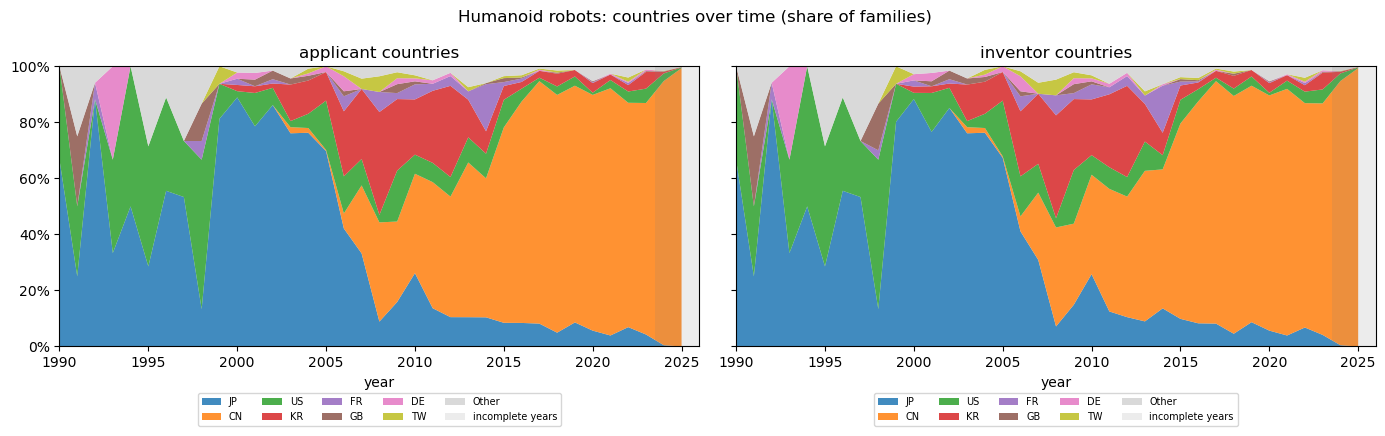

In [62]:
fig, axes = side_by_side(f"{SECTOR_NAME}: countries over time (share of families)", sharey=True)
for ax, role in zip(axes, ("applicant", "inventor")):
    stack_100(ax, share_over_time(pool_other(countries[countries["role"] == role], "ctry"), "ctry"), f"{role} countries")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5, fontsize=7)
plt.tight_layout()
plt.show()


The same shares on a world map (complete years). The colour scale is a square root, so that the countries with small shares are visible next to the largest one. The figure is also saved in outputs/step1/ for the deck.


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Not on the map (country: % of applicants, % of inventors): AE 0.0%, 0.0%, HK 0.1%, 0.2%, KP 0.0%, 0.0%, LK 0.0%, 0.0%, MC 0.0%, 0.1%, NP 0.0%, 0.0%, OM 0.0%, 0.1%, PE 0.1%, 0.0%, SG 0.0%, 0.0%, TN 0.0%, 0.0%


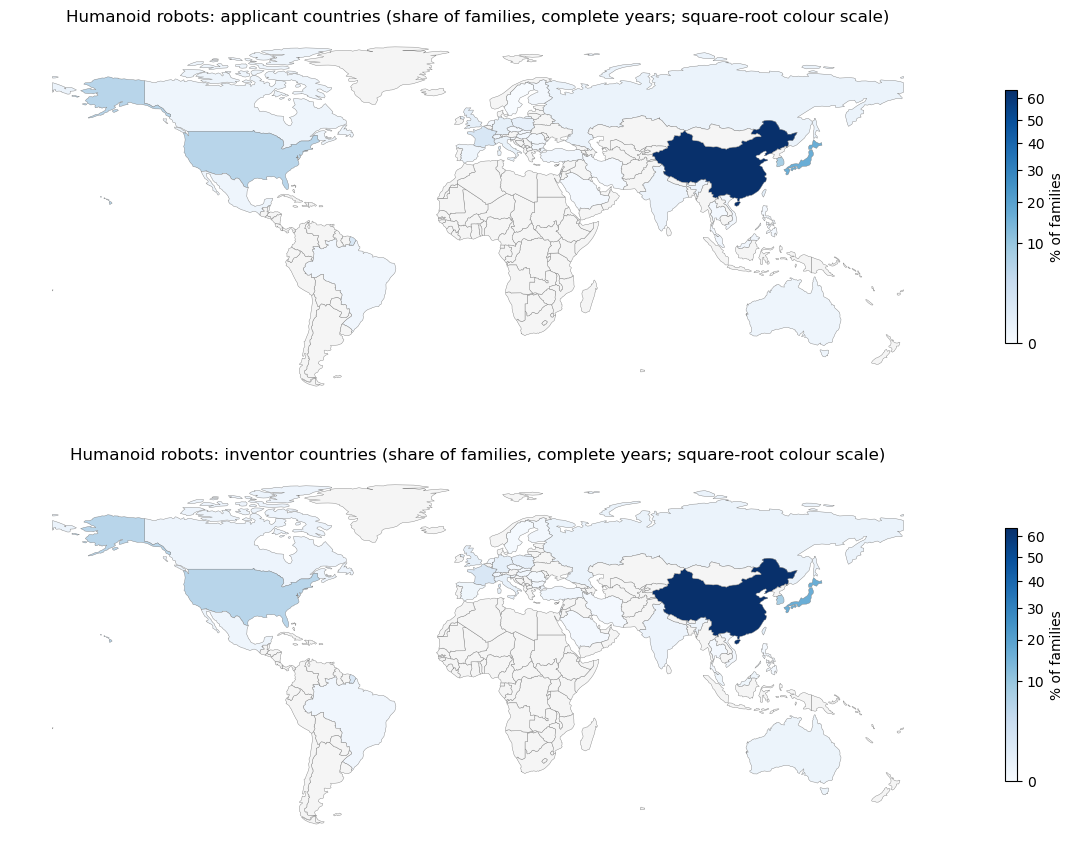

In [63]:
%pip install -q "geopandas<1.0"        # the 0.x versions have the Natural Earth world map inside: no download needed
import warnings

import geopandas as gpd
from matplotlib.colors import PowerNorm

ISO3 = {  # country codes of PATSTAT (2 letters) -> codes of the map (3 letters): the countries that file most patents
    "AR": "ARG", "AT": "AUT", "AU": "AUS", "BE": "BEL", "BG": "BGR", "BR": "BRA", "BY": "BLR", "CA": "CAN", "CH": "CHE", "CL": "CHL",
    "CN": "CHN", "CO": "COL", "CZ": "CZE", "DE": "DEU", "DK": "DNK", "EE": "EST", "EG": "EGY", "ES": "ESP", "FI": "FIN", "FR": "FRA",
    "GB": "GBR", "GR": "GRC", "HR": "HRV", "HU": "HUN", "ID": "IDN", "IE": "IRL", "IL": "ISR", "IN": "IND", "IR": "IRN", "IS": "ISL",
    "IT": "ITA", "JP": "JPN", "KR": "KOR", "KZ": "KAZ", "LT": "LTU", "LU": "LUX", "LV": "LVA", "MX": "MEX", "MY": "MYS", "NL": "NLD",
    "NO": "NOR", "NZ": "NZL", "PH": "PHL", "PK": "PAK", "PL": "POL", "PT": "PRT", "RO": "ROU", "RS": "SRB", "RU": "RUS", "SA": "SAU",
    "SE": "SWE", "SI": "SVN", "SK": "SVK", "TH": "THA", "TR": "TUR", "TW": "TWN", "UA": "UKR", "US": "USA", "VN": "VNM", "ZA": "ZAF",
}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # geopandas 0.x warns that its built-in datasets will disappear in 1.0: here we want exactly that file
    world = gpd.read_file(gpd.datasets.get_path("naturalearth_lowres"))
world = world[world["name"] != "Antarctica"]

map_shares = complete_years(countries).pivot_table(index="ctry", columns="role", values="n_frac", aggfunc="sum", fill_value=0)
map_shares = map_shares / map_shares.sum() * 100                     # % of the families, each role sums to 100
map_shares["iso3"] = map_shares.index.map(ISO3)
off_map = map_shares[~map_shares["iso3"].isin(world["iso_a3"])]       # codes that are not in my list or not on the map (e.g. HK, SG)
print("Not on the map (country: % of applicants, % of inventors): "
      + (", ".join(f"{c} {r.applicant:.1f}%, {r.inventor:.1f}%" for c, r in off_map.iterrows()) or "none"))

fig, axes = plt.subplots(2, 1, figsize=(12, 9))
for ax, role in zip(axes, ("applicant", "inventor")):
    merged = world.merge(map_shares[["iso3", role]], left_on="iso_a3", right_on="iso3", how="left")
    merged.plot(column=role, ax=ax, cmap="Blues", norm=PowerNorm(0.5, vmin=0, vmax=map_shares[role].max()), edgecolor="grey",
                linewidth=0.3, legend=True, legend_kwds={"label": "% of families", "shrink": 0.6}, missing_kwds={"color": "whitesmoke"})
    ax.set_title(f"{SECTOR_NAME}: {role} countries (share of families, complete years; square-root colour scale)")
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "countries_map.png", dpi=200, bbox_inches="tight")      # for the deck
plt.show()

#### Heat map: applicant countries year by year

The same fractional counts as the table above, by priority year. By default the countries completed with the office of first filing are included (about two thirds of the families in the last run): for China, Japan and Korea the rows are partly a proxy, as explained above. Setting `only_known = True` shows only the families with a country in PATSTAT; setting `role = "inventor"` shows the inventor countries. The colour scale is a square root, as in the map.

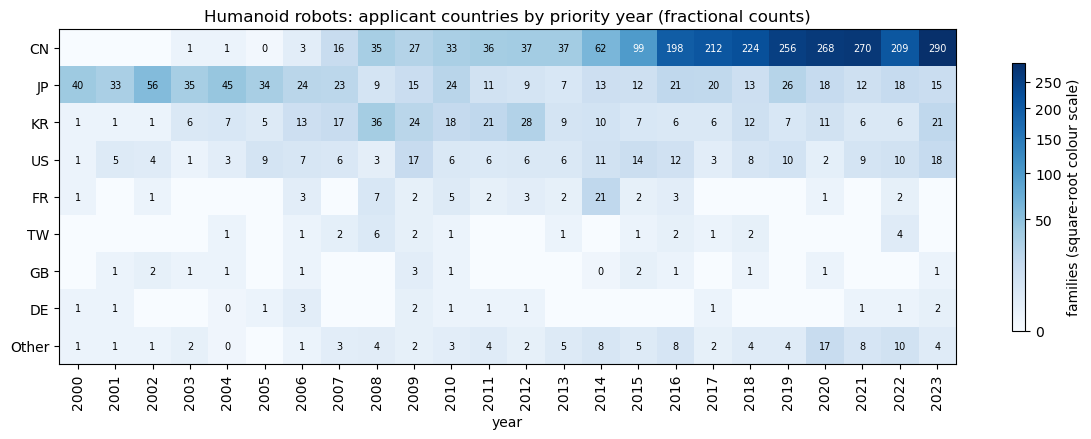

In [64]:
role = "applicant"          # "inventor" for the inventor countries
only_known = False          # True: we leave out the families whose country we completed with the office of first filing

c = countries[countries["role"] == role]
if only_known:
    c = c[c["source"] == "known"]
c = pool_other(c, "ctry")                                               # we keep the TOP_N countries and pool the rest in Other, as in the tables above
ctry_table = (c.pivot_table(index="ctry", columns="year", values="n_frac", aggfunc="sum", fill_value=0)
              .loc[:, HEAT_FROM:LAST_COMPLETE_YEAR])
order = [s for s in ctry_table.sum(axis=1).sort_values(ascending=False).index if s != "Other"]
ctry_table = ctry_table.loc[order + (["Other"] if "Other" in ctry_table.index else [])]

heatmap(ctry_table, f"{SECTOR_NAME}: {role} countries by priority year (fractional counts"
        + (", known countries only)" if only_known else ")"),
        "families (square-root colour scale)", f"{role}_countries_heatmap", norm=PowerNorm(0.5, vmin=0))

#### Heat map: where each country protects its inventions

For the six applicant countries with most families, the share of their families that have an application at each IP5 office (rows do not add up to 100%, because a family can be filed at several offices). A strong cell outside the home office means that the country's applicants go abroad to that market.

Two cautions. First, we use only the families with a known applicant country (about one third of the sector), and they are not a random third: PATSTAT leaves the country empty for most families filed only in China, so those families are under-represented here and the Chinese column is probably understated. Second, the numbers in brackets are small for some countries, so we read the pattern and not the single percentages.

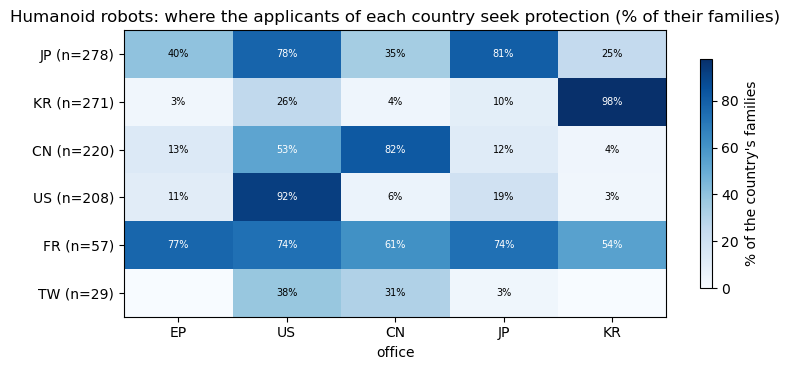

In [65]:
# only the families whose applicant country is known in PATSTAT: with the completed countries every Chinese family would trivially be "home"
known = countries[(countries["role"] == "applicant") & (countries["source"] == "known")]
known = complete_years(known)[["docdb_family_id", "ctry"]].drop_duplicates()
at_office = (applications.loc[applications["appln_auth"].isin(IP5_OFFICES), ["docdb_family_id", "appln_auth"]]
             .drop_duplicates())
pairs = known.merge(at_office, on="docdb_family_id")

n_ctry = known.groupby("ctry")["docdb_family_id"].nunique()       # families of each country (a family with applicants from two countries counts in both)
top6 = n_ctry.nlargest(6).index
home_abroad = (pairs[pairs["ctry"].isin(top6)].groupby(["ctry", "appln_auth"])["docdb_family_id"].nunique()
               .unstack(fill_value=0).reindex(index=top6, columns=list(IP5_OFFICES), fill_value=0))
home_abroad = home_abroad.div(n_ctry[top6], axis=0) * 100              # each row is read as a share of the families of that country
home_abroad.index = [f"{x} (n={n_ctry[x]:,})" for x in home_abroad.index]
home_abroad.columns.name = "office"

heatmap(home_abroad, f"{SECTOR_NAME}: where the applicants of each country seek protection (% of their families)",
        "% of the country's families", "home_abroad_heatmap", fmt="{:.0f}%", figsize=(8, 3.8))

### 9.3 Sensitivity: only the families filed in at least two offices

Many families, above all in China, are filed in one office only. To see how much they weigh on the country shares, we repeat the applicant table on the families filed in at least two national offices (the PCT application is not counted as an office). This is a check on the result, not another definition of the sector: a family filed in one office only can be valuable.

In [66]:
international = set(families.loc[families["n_jurisdictions"] >= 2, "docdb_family_id"])
applicants_ = complete_years(countries[countries["role"] == "applicant"])
by_ctry = pd.DataFrame({
    "all families": applicants_.groupby("ctry")["n_frac"].sum(),
    "families in >= 2 offices": applicants_[applicants_["docdb_family_id"].isin(international)].groupby("ctry")["n_frac"].sum(),
}).fillna(0)
top = by_ctry["all families"].nlargest(TOP_N).index
by_ctry = by_ctry.groupby(by_ctry.index.where(by_ctry.index.isin(top), "Other")).sum()
print(f"Families in >= 2 offices: {100 * mature['n_jurisdictions'].ge(2).mean():.1f}% of the sector (complete years)")
pct_format(share_table(by_ctry))

Families in >= 2 offices: 15.5% of the sector (complete years)


,all families,families in >= 2 offices
ctry,,
CN,64.1%,19.8%
JP,16.2%,42.5%
KR,7.7%,12.1%
US,5.6%,8.3%
FR,1.6%,7.9%
TW,0.7%,1.3%
GB,0.5%,1.3%
DE,0.5%,1.4%
Other,3.0%,5.4%


## 10. Appropriability: patents or secrecy?

Patents are only one way to protect an invention: a firm can also rely on secrecy, on being first (lead time) or on complementary assets. If a field relies mostly on secrecy, patent counts show only part of its activity. Patent data cannot measure secrecy directly, so we do two things: (1) we look in our data for signals that the field uses patents seriously (they are signals, not a proof); (2) we read them together with the literature and write one argued paragraph for the deck.

### 10.1 Signals in our data

For each period of priority years (complete years only): how many families, how many go through the PCT, how many are filed in at least two offices, the mean number of applications per family, the share of families with at least one granted application, and the share with a computing or AI class (G06, G10L). We use the mean and not the median of the applications per family because the median is 1 in every period and says nothing. The grant share is a lower bound for the recent periods, because an application takes years to be examined: we compare the older periods with each other and we read the last one with care. The last row is my proxy for the part of the technology (learning and control software) that firms often protect with secrecy or copyright rather than with patents.

In [67]:
periods = pd.cut(mature["priority_year"], bins=[YEAR_MIN - 1, 1999, 2009, 2019, LAST_COMPLETE_YEAR],
                 labels=[f"{YEAR_MIN}-1999", "2000-2009", "2010-2019", f"2020-{LAST_COMPLETE_YEAR}"])

computing = set(family_cpc.loc[~family_cpc["is_tagging"] & family_cpc["subclass"].str.startswith(("G06", "G10L")), "docdb_family_id"])
# a family counts as granted if at least one of its applications is granted (each office decides on its own)
has_granted = applications.assign(is_granted=applications["granted"].eq("Y")).groupby("docdb_family_id")["is_granted"].any()

# the mean, not the median, of the applications per family: the median is 1 in every period
signals = pd.DataFrame({
    "families": mature.groupby(periods, observed=True).size(),
    "via PCT (%)": 100 * mature["has_pct"].astype(float).groupby(periods, observed=True).mean(),
    "filed in >= 2 offices (%)": 100 * (mature["n_jurisdictions"] >= 2).groupby(periods, observed=True).mean(),
    "mean applications per family": mature["n_applns"].groupby(periods, observed=True).mean(),
    "with a granted application (%)": 100 * mature["docdb_family_id"].map(has_granted).astype(float).groupby(periods, observed=True).mean(),
    "with a computing / AI class, G06 or G10L (%)": 100 * mature["docdb_family_id"].isin(computing).groupby(periods, observed=True).mean(),
}).T.rename_axis(columns=None)
signals.round(1)

,1990-1999,2000-2009,2010-2019,2020-2023
families,96.0,622.0,1655.0,1236.0
via PCT (%),12.5,21.4,10.2,11.2
filed in >= 2 offices (%),40.6,32.2,11.4,10.7
mean applications per family,2.3,2.3,1.5,1.4
with a granted application (%),86.5,64.5,62.7,55.6
"with a computing / AI class, G06 or G10L (%)",4.2,4.7,6.3,7.6


**Who files?** Applicant types, fractional counts (every family sums to 1), by period. A large share of universities and research institutes means that part of the patenting is academic, not a commercial protection strategy.

In [68]:
types = (family_applicants.merge(mature[["docdb_family_id", "priority_year"]], on="docdb_family_id")
         .assign(period=lambda d: pd.cut(d["priority_year"], bins=[YEAR_MIN - 1, 1999, 2009, 2019, LAST_COMPLETE_YEAR],
                                         labels=[f"{YEAR_MIN}-1999", "2000-2009", "2010-2019", f"2020-{LAST_COMPLETE_YEAR}"])))
type_counts = types.pivot_table(index="applicant_type", columns="period", values="weight", aggfunc="sum", fill_value=0, observed=True)
pct_format(share_table(type_counts).rename_axis(columns=None))

,1990-1999,2000-2009,2010-2019,2020-2023
applicant_type,,,,
COMPANY,57.7%,41.3%,38.8%,44.2%
INDIVIDUAL,36.7%,30.0%,10.8%,3.0%
GOV NON-PROFIT,2.2%,7.5%,4.1%,3.3%
UNIVERSITY,1.7%,18.3%,44.8%,38.3%
UNKNOWN,1.6%,1.7%,0.7%,9.5%
COMPANY GOV NON-PROFIT,0.0%,0.2%,0.0%,0.0%
GOV NON-PROFIT UNIVERSITY,0.0%,0.8%,0.9%,1.5%
HOSPITAL,0.0%,0.0%,0.0%,0.2%
Total,100.0%,100.0%,100.0%,100.0%


### 10.2 What we argue

1. **Patenting is intense, but mostly domestic and partly academic.** Since 2000 the sector's families grow by 9.3% a year, against 4.7% for all patents, and in 2024, which is almost complete, they almost double (351 to 664 families; Section 7.2). Chinese applicants hold 64% of the families of the complete years (Section 9.2; where the country of the applicant is unknown I use the office of first filing). Only 10.7% of the families of 2020-2023 are filed in at least two offices (40.6% in the 1990s) and 11.2% go through the PCT. Filing abroad costs money and signals an invention worth protecting: most of the recent growth does not carry this signal, and among the families filed in at least two offices Japan leads with 43%, China has 20% (Section 9.3). Universities hold 38% of the families of 2020-2023, companies 44%: part of the patenting is academic, not a commercial protection choice.
2. **Patents see only part of the technology.** Only 7.6% of the families of 2020-2023 have a computing or AI class (G06, G10L), up from 4.2% in the 1990s, although perception, learning and control software is central to a humanoid robot. In the literature, the choice between patenting, publishing and secrecy depends on how much value the firm can capture and on its freedom to operate (Holgersson and Wallin, 2017; Bos, Broekhuizen and de Faria, 2015), and firms in most manufacturing industries rate secrecy and lead time above patents (Cohen, Nelson and Walsh, 2000). What we see in the data is also what applicants chose to disclose: in the US, most applicants accept early publication of their applications (Graham and Hegde, 2015). A sign for our sector: in June 2025 Tesla sued a former Optimus engineer for taking files on the actuation of robot hands; the case was settled in June 2026. I found no academic study on appropriability specific to humanoid robots: the evidence comes from manufacturing in general and from one case in the press.
3. **What it means for the next steps.** Patent counts measure the hardware side well (manipulators, legs, joints: 73% of the families are in Mechanical engineering) and are a lower bound for the software and AI side. Because much of the recent volume is domestic and academic, counts can overstate the commercial weight of the technology. I state these limits in the deck and I read the scores of Steps 3 and 4 with them.

**Sources**

- Cohen, W. M., Nelson, R. R., Walsh, J. P. (2000), Protecting Their Intellectual Assets: Appropriability Conditions and Why U.S. Manufacturing Firms Patent (or Not), NBER Working Paper 7552. https://www.nber.org/papers/w7552
- Holgersson, M., Wallin, M. W. (2017), The patent management trichotomy: patenting, publishing, and secrecy, Management Decision. https://research.chalmers.se/en/publication/245926
- Bos, B., Broekhuizen, T. L. J., de Faria, P. (2015), A dynamic view on secrecy management, Journal of Business Research 68(12), 2619-2627. https://ideas.repec.org/a/eee/jbrese/v68y2015i12p2619-2627.html
- Graham, S. J. H., Hegde, D. (2015), Disclosing Patents' Secrets, Science, Volume 347, Issue 6219, pp. 236-237. https://www.stern.nyu.edu/experience-stern/news/hegde-disclosing-patent-secrets
- TechCrunch, "Tesla sues former Optimus engineer over alleged trade secret theft", 12 June 2025. https://techcrunch.com/2025/06/12/tesla-sues-former-optimus-engineer-over-alleged-trade-secret-theft
- The Next Web, 29 June 2026, on the settlement between Tesla and Proception. https://thenextweb.com/news/proception-robot-hand-tesla-trade-secret-settlement-seed-round

---

← [01 · PATSTAT on TIP](01_patstat_basics.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md) &nbsp;|&nbsp; — →